# Detect differential item functioning with TIRT

Two people with the same traits have the same choice probabilities if their
group membership affects only the trait distribution. In this simulated
example, three pairs also have group-specific thresholds.

For pair $j$, let the signed utility difference be

$$
\eta_{ij} = a_{j1}\theta_{it_1}-a_{j2}\theta_{it_2}+u_{j1}-u_{j2}.
$$

The $a$ terms are signed loadings, the $t$ indices select traits, and the $u$
terms are statement effects. With unit comparison residual variance, the
probability of preferring the first statement is
$\Phi(\eta_{ij}-b_j-\delta_{jg})$, where $b_j$ is the baseline threshold and
$\delta_{jg}$ is the measurement effect for group $g$.

Both trait means are fixed at zero in the reference group. The focal group
means are estimated. The groups have residual trait SDs of one and share one
estimated trait correlation. The generating loadings are known and the statement effects are zero in
this simulation. Most pair thresholds are invariant, and the DIF priors use
shrinkage to help separate threshold differences from group mean differences.

In [1]:
import arviz_stats as azs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import ndtr

import pyfcirt as fc

## Generate one dataset

Simulate 400 people answering 12 two-statement blocks. The focal group mean
shifts are 0.45 and −0.30. The threshold differences are zero except for
blocks B02, B06 and B10, whose changes are 1.5, −1.5 and 1.5 respectively.

In [2]:
rng = np.random.default_rng(730026)
n = 400
blocks = [f"B{i:02d}" for i in range(1, 13)]
traits = np.asarray([(0, 0)] * 4 + [(1, 1)] * 4 + [(0, 1)] * 4)
group = rng.permutation(np.repeat([0, 1], n // 2))
people = pd.DataFrame({"person_id": np.arange(n), "site": np.where(group, "B", "A")})
people["site"] = pd.Categorical(people["site"], categories=["A", "B"])
theta = rng.multivariate_normal([0, 0], [[1, 0.35], [0.35, 1]], size=n)
theta += group[:, None] * np.array([0.45, -0.30])

loadings = np.tile([0.9, 1.1], (len(blocks), 1))
keying = np.tile([1, -1], (len(blocks), 1))
keying[-2:, 1] = 1
design = pd.DataFrame(
    [
        (block, j + 1, f"{block}_{j + 1}", f"T{traits[k, j] + 1}", keying[k, j])
        for k, block in enumerate(blocks)
        for j in (0, 1)
    ],
    columns=["block_id", "position", "statement_id", "trait", "keying"],
)
effect = np.zeros(len(blocks))
effect[[1, 5, 9]] = [1.5, -1.5, 1.5]
utility = (theta[:, traits] * loadings * keying) @ np.array([1, -1])
threshold = np.linspace(-0.5, 0.5, len(blocks)) + group[:, None] * effect
choices = (utility + rng.normal(size=threshold.shape) >= threshold).astype(int)
responses = pd.DataFrame(
    {
        "person_id": np.repeat(people.person_id.to_numpy(), len(blocks)),
        "block_id": np.tile(blocks, n),
        "response": choices.ravel(),
    }
)
responses.head()

,person_id,block_id,response
0,0,B01,1
1,0,B02,1
2,0,B03,1
3,0,B04,1
4,0,B05,1


## Fit each DIF prior to the same choices

The three priors differ in how they shrink threshold changes. The
hierarchical prior shrinks each change toward zero. Pairwise L1 shrinks
the absolute group difference on a zero-sum scale. Truncated L1 caps
that penalty per group pair and adds a normal base distribution.
All three fits use the default DIF priors and the optional NumPyro sampler.
Install the `numpyro` extra to run these fits. See
[estimation backends](../examples/estimation_backends.md#calibrate-with-nuts).

In [3]:
specification = fc.TIRT(
    loading_anchors=dict(zip(design.statement_id, loadings.ravel(), strict=True)),
    residuals="fixed",
)
inputs = fc.FCInput(
    design,
    fc.ResponseTable(responses, format="block_long"),
    model=specification,
    response_format=None,
    scale=fc.CategoryScale((0, 1)),
)
population = fc.PopulationSpec(
    group="site",
    reference_group="A",
    theta_correlation="shared",
)
priors = {
    "Hierarchical": ("hierarchical", 700, 1100),
    "Pairwise L1": ("pairwise_l1", 2000, 2200),
    "Truncated L1": ("truncated_l1", 2000, 2200),
}
fits, diagnostics = {}, []
# Compare the same data, with longer chains for the L1 priors.
for label, (prior, draws, warmup) in priors.items():
    model = fc.Model().prepare(inputs, person_data=people, population=population)
    model.add_dif_terms(
        "fc.cutpoints",
        person_data=people,
        groups="site",
        prior=prior,
    )
    idata = model.fit(
        draws=draws,
        tune=warmup,
        chains=4,
        random_seed=33,
        nuts_sampler="numpyro",
        progressbar=False,
    )
    fits[label] = model
    variables = [
        "cutpoint",
        "regression_coefficient",
        "theta",
        "population_mean",
        "trait_correlation",
    ]
    rhat = azs.rhat(idata.posterior.dataset[variables])
    diagnostics.append(
        {
            "Prior": label,
            "Maximum R-hat": max(float(rhat[name].max()) for name in rhat),
            "Divergences": int(idata.sample_stats.dataset.diverging.sum()),
        }
    )
pd.DataFrame(diagnostics).round(3)

,Prior,Maximum R-hat,Divergences
0,Hierarchical,1.014,0
1,Pairwise L1,1.008,0
2,Truncated L1,1.015,0


## Compare the thresholds

Positive differences mean group B needs a larger utility advantage to
prefer the first statement. The bars show 95% equal-tailed posterior
intervals. The diamonds mark the differences used to generate the data.

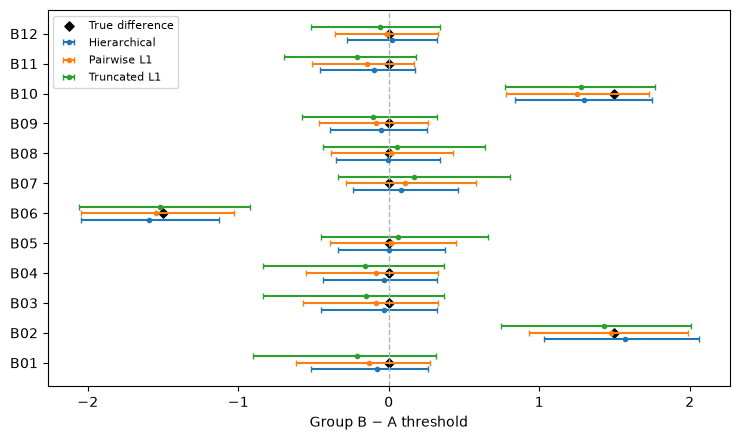

In [4]:
contrasts = pd.concat(
    [model.dif_summary({"site": ("A", "B")}).assign(Prior=label) for label, model in fits.items()],
    ignore_index=True,
)
contrasts["Block"] = contrasts.units.str[0]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
groups = contrasts.groupby("Prior", sort=False)
for offset, (name, rows) in zip((-0.22, 0, 0.22), groups, strict=True):
    ax.errorbar(
        rows["mean"],
        np.arange(len(blocks)) + offset,
        xerr=[rows["mean"] - rows.lower, rows.upper - rows["mean"]],
        fmt="o",
        ms=3,
        capsize=2,
        label=name,
    )
ax.scatter(effect, np.arange(len(blocks)), marker="D", s=22, c="black", label="True difference")
ax.axvline(0, color="0.7", ls="--", lw=1)
ax.set(yticks=np.arange(len(blocks)), yticklabels=blocks, xlabel="Group B − A threshold")
ax.legend(loc="best", fontsize=8)
fig.tight_layout()
plt.show()

## Interpret probabilities at a fixed trait level

At zero on both traits, the utility difference for B02 comes from its two
statement effects. Plug the posterior means of those effects and the
group-specific thresholds into the choice probability. Both groups use
the same utility difference.

In [5]:
pair = design.loc[design.block_id == "B02", "statement_id"]
utility = {}
for label, model in fits.items():
    effects = fc.coef(model, blocks=["B02"], var_names=["statement_effect"], kind="stats")
    means = effects.reset_index().set_index("statement").loc[pair, "mean"]
    utility[label] = means.iloc[0] - means.iloc[1]

illustrated = contrasts.query("Block == 'B02'").copy()
eta = illustrated.Prior.map(utility)
illustrated["P(first | A)"] = ndtr(eta - illustrated.reference_mean)
illustrated["P(first | B)"] = ndtr(eta - illustrated.compared_mean)
illustrated["B − A"] = illustrated["P(first | B)"] - illustrated["P(first | A)"]
illustrated[["Prior", "P(first | A)", "P(first | B)", "B − A"]].set_index("Prior").round(3)

,P(first | A),P(first | B),B − A
Prior,,,
Hierarchical,0.698,0.147,-0.551
Pairwise L1,0.696,0.168,-0.528
Truncated L1,0.700,0.183,-0.517


The interval check addresses each contrast separately. To keep only
contrasts whose 95% interval excludes zero, use
`model.dif_summary(significant_only=True)`. See
[DIF options](../reference/dif.md) for joint groups, numeric contrasts and
target-specific priors.